## Delivery Tasks Accepted in Bursts (Flag 15)

### Dataset Overview

One constructed courier workday with 96 distinct delivery tasks in 8 acceptance bursts, 46 service stops, and 1419 GPS points. Some stops serve multiple orders at the same building entrance; each order has a distinct completion time inside the recorded stationary service interval. Small bursts contain at most four tasks. The existing route and workday duration are unchanged.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze how the courier handles tasks accepted close together in time.

Role: Last-mile delivery operations analyst


Category: acceptance bursts, within-burst spatial sequencing, and burst splitting


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Do accepted delivery tasks arrive continuously or in distinct bursts?

#### Analysis action

Order tasks by acceptance time and compare within-burst with between-burst inter-arrival gaps.

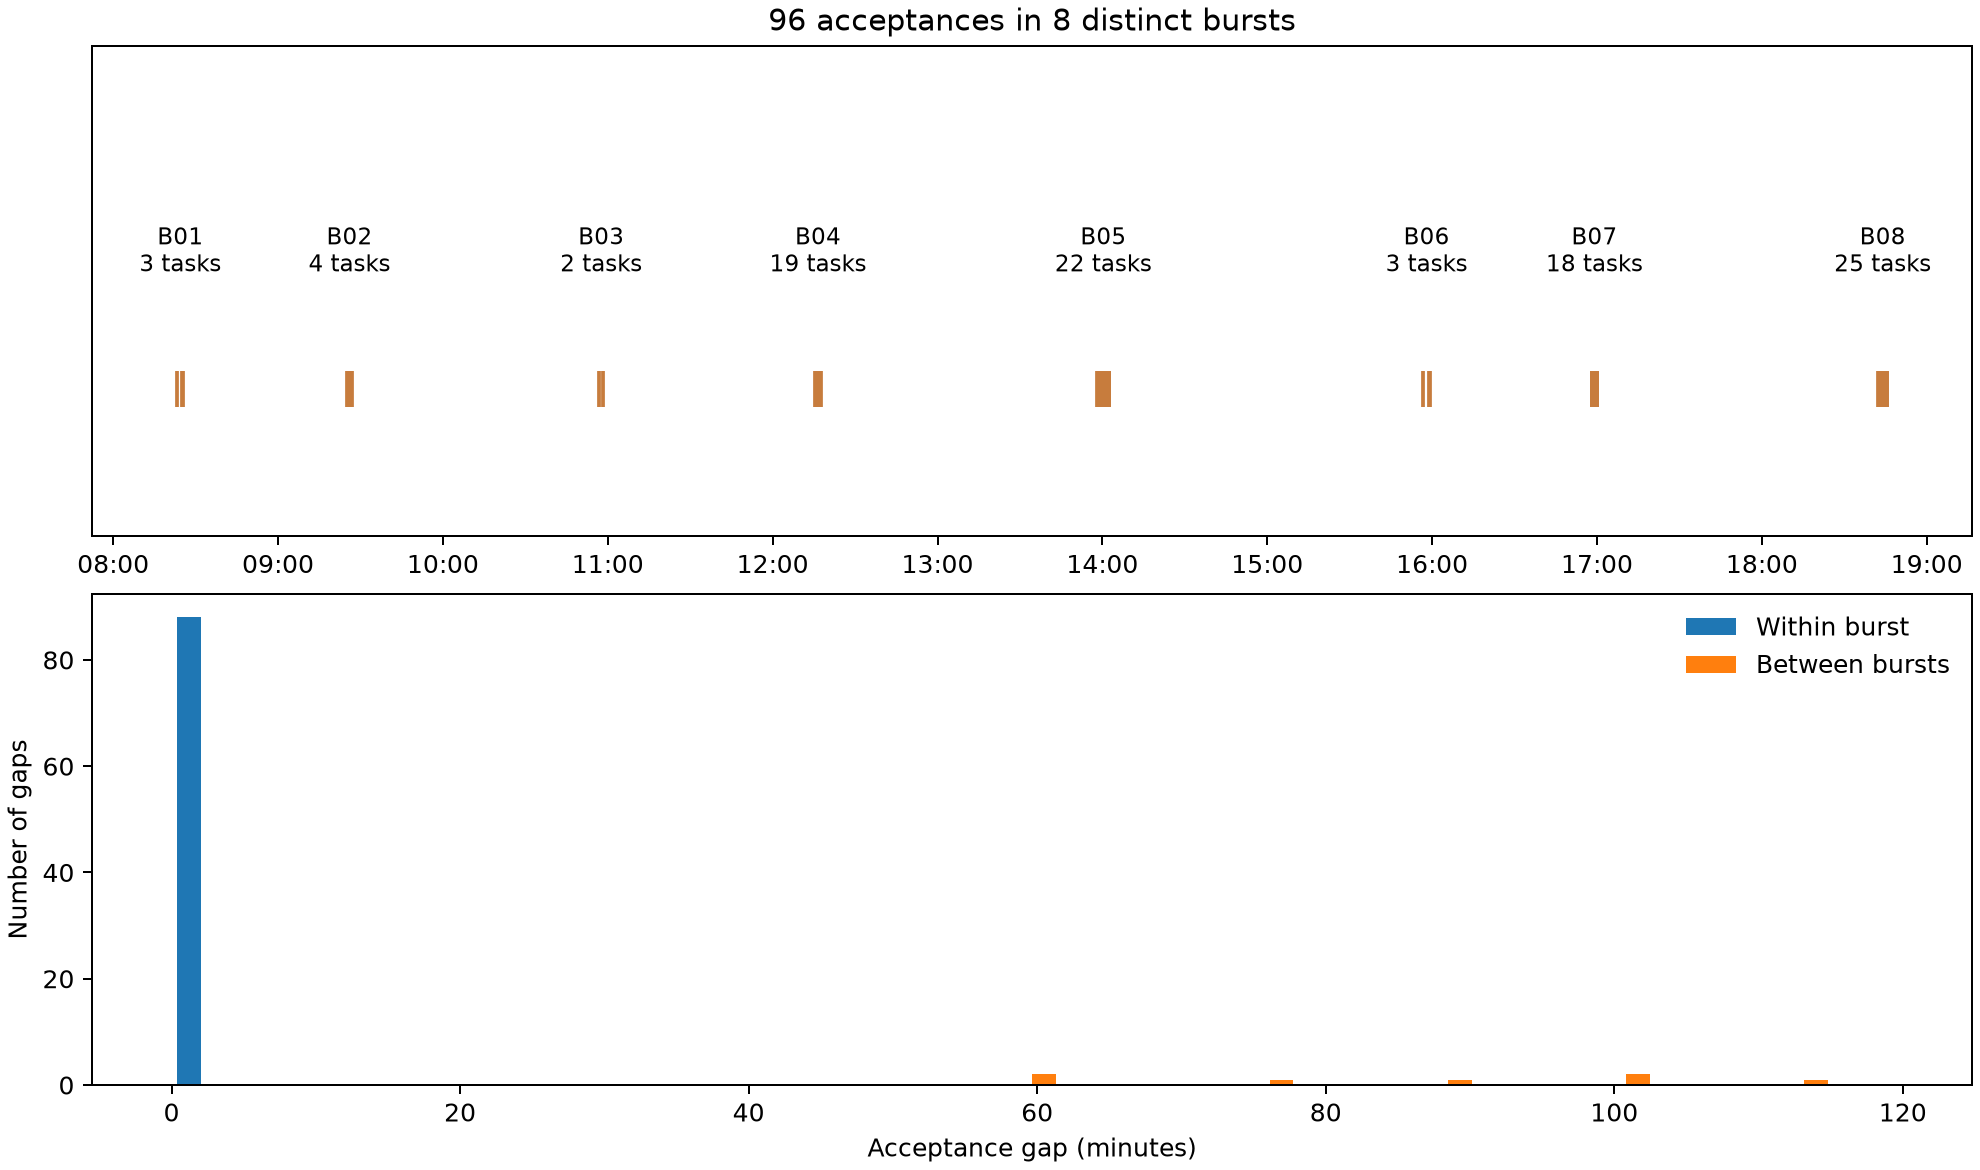

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def analyze(df, index):
    import matplotlib.dates as mdates

    d = df.copy()
    d["accept_time"] = pd.to_datetime(d.accept_time)
    b = d.groupby("acceptance_burst_id").agg(
        tasks=("delivery_task_id", "size"),
        groups=("spatial_group", "nunique"),
        start=("accept_time", "min"),
        end=("accept_time", "max"),
    )
    b["size"] = np.where(b.tasks <= 4, "small", "large")
    within = (
        d.sort_values("accept_time")
        .groupby("acceptance_burst_id")
        .accept_time.diff()
        .dt.total_seconds()
        .dropna()
        / 60
    )
    between = (b.start - b.end.shift()).dt.total_seconds().dropna() / 60
    rates = []
    for column in ["acceptance_order_in_burst", "completion_order_in_burst"]:
        pairs = []
        for _, q in d.groupby("acceptance_burst_id"):
            if q.spatial_group.nunique() > 1:
                values = q.sort_values(column).spatial_group.to_numpy()
                pairs.extend(values[1:] == values[:-1])
        rates.append(float(np.mean(pairs)))
    split = b.groupby("size")["groups"].apply(lambda v: float((v > 1).mean()))
    if index == 0:
        evidence = dict(
            acceptance_bursts=len(b),
            accepted_tasks=len(d),
            maximum_within_burst_gap_min=round(float(within.max()), 2),
            minimum_between_burst_gap_min=round(float(between.min()), 2),
        )
        fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), constrained_layout=True)
        axes[0].scatter(
            d.accept_time, np.zeros(len(d)), marker="|", s=200, color="#c77c3d"
        )
        for name, row in b.iterrows():
            axes[0].text(
                row.start + (row.end - row.start) / 2,
                0.12,
                f"{name}\n{row.tasks} tasks",
                ha="center",
                fontsize=9,
            )
        axes[0].set(
            yticks=[],
            ylim=(-0.15, 0.35),
            title=f"{len(d)} acceptances in {len(b)} distinct bursts",
        )
        axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        axes[1].hist(
            [within, between],
            bins=np.linspace(0, max(between) + 5, 30),
            label=["Within burst", "Between bursts"],
        )
        axes[1].set(xlabel="Acceptance gap (minutes)", ylabel="Number of gaps")
        axes[1].legend(frameon=False)
    elif index == 1:
        evidence = dict(
            same_group_adjacency_in_acceptance_sequence=round(rates[0], 3),
            same_group_adjacency_in_completion_sequence=round(rates[1], 3),
        )
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
        q = d[d.acceptance_burst_id == "B04"]
        palette = dict(
            zip(sorted(q.spatial_group.unique()), ["#3976a8", "#c77c3d", "#4f846c"])
        )
        for y, column in enumerate(
            ["acceptance_order_in_burst", "completion_order_in_burst"]
        ):
            for group, rows in q.groupby("spatial_group"):
                axes[0].scatter(
                    rows[column],
                    np.full(len(rows), y),
                    color=palette[group],
                    s=75,
                    label=group.split("_")[-1] if y == 0 else None,
                )
        axes[0].set(
            yticks=[0, 1],
            yticklabels=["Acceptance", "Completion"],
            ylim=(-0.5, 1.5),
            xlabel="Task position in sequence",
            title="B04: destination groups in each sequence",
        )
        axes[0].legend(title="Spatial group", frameon=False)
        axes[1].bar(["Acceptance", "Completion"], rates, color=["#71808d", "#4f846c"])
        for i, rate in enumerate(rates):
            axes[1].text(i, rate + 0.025, f"{rate:.1%}", ha="center")
        axes[1].set(
            ylim=(0, 1.08),
            ylabel="Same-group share of adjacent task pairs",
            title="All multi-group bursts",
        )
    else:
        evidence = dict(
            small_burst_split_rate=round(split["small"], 3),
            large_burst_split_rate=round(split["large"], 3),
        )
        fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
        for name, row in b.iterrows():
            ax.scatter(
                row.tasks,
                row["groups"],
                s=90,
                color="#3976a8" if row["size"] == "small" else "#c77c3d",
            )
            ax.annotate(
                name,
                (row.tasks, row["groups"]),
                xytext=(5, 7),
                textcoords="offset points",
            )
        ax.set(
            xlabel="Tasks accepted in burst (small: ≤4)",
            ylabel="Distinct destination groups",
            yticks=[1, 2, 3],
            ylim=(0.7, 3.4),
            title="Burst size and spatial splitting",
        )
    print(evidence)
    return evidence


evidence = analyze(df, 0)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/delivery_acceptance_bursts.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "delivery_acceptance_event_timeline",
  "insight_type": "overall_pattern",
  "insight": "New delivery tasks are accepted in several distinct bursts rather than arriving uniformly throughout the workday.",
  "insight_value": {
    "acceptance_bursts": 8,
    "accepted_tasks": 96,
    "maximum_within_burst_gap_min": 1.83,
    "minimum_between_burst_gap_min": 58.98
  },
  "plot": {
    "plot_type": "event_timeline_and_gap_histograms",
    "title": "Delivery Acceptance Bursts",
    "file": "visualizations/delivery_acceptance_bursts.png",
    "description": "Acceptance marks and gap distributions distinguish dense within-burst arrivals from long inter-burst intervals."
  },
  "question": "Do accepted delivery tasks arrive continuously or in distinct bursts?",
  "actionable_insight": "Order tasks by acceptance time and compare within-burst with between-burst inter-arrival gaps.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef analyze(df, index):\n    import matplotlib.dates as mdates\n    d = df.copy()\n    d['accept_time'] = pd.to_datetime(d.accept_time)\n    b = d.groupby('acceptance_burst_id').agg(\n        tasks=('delivery_task_id', 'size'), groups=('spatial_group', 'nunique'),\n        start=('accept_time', 'min'), end=('accept_time', 'max'))\n    b['size'] = np.where(b.tasks <= 4, 'small', 'large')\n    within = d.sort_values('accept_time').groupby('acceptance_burst_id').accept_time.diff().dt.total_seconds().dropna()/60\n    between = (b.start-b.end.shift()).dt.total_seconds().dropna()/60\n    rates = []\n    for column in ['acceptance_order_in_burst', 'completion_order_in_burst']:\n        pairs = []\n        for _, q in d.groupby('acceptance_burst_id'):\n            if q.spatial_group.nunique() > 1:\n                values = q.sort_values(column).spatial_group.to_numpy()\n                pairs.extend(values[1:] == values[:-1])\n        rates.append(float(np.mean(pairs)))\n    split = b.groupby('size')['groups'].apply(lambda v: float((v > 1).mean()))\n    if index == 0:\n        evidence = dict(acceptance_bursts=len(b), accepted_tasks=len(d),\n            maximum_within_burst_gap_min=round(float(within.max()), 2),\n            minimum_between_burst_gap_min=round(float(between.min()), 2))\n        fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), constrained_layout=True)\n        axes[0].scatter(d.accept_time, np.zeros(len(d)), marker='|', s=200, color='#c77c3d')\n        for name, row in b.iterrows():\n            axes[0].text(row.start+(row.end-row.start)/2, .12, f'{name}\\n{row.tasks} tasks', ha='center', fontsize=9)\n        axes[0].set(yticks=[], ylim=(-.15, .35), title=f'{len(d)} acceptances in {len(b)} distinct bursts')\n        axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))\n        axes[1].hist([within, between], bins=np.linspace(0, max(between)+5, 30), label=['Within burst', 'Between bursts'])\n        axes[1].set(xlabel='Acceptance gap (minutes)', ylabel='Number of gaps')\n        axes[1].legend(frameon=False)\n    elif index == 1:\n        evidence = dict(same_group_adjacency_in_acceptance_sequence=round(rates[0], 3),\n            same_group_adjacency_in_completion_sequence=round(rates[1], 3))\n        fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)\n        q = d[d.acceptance_burst_id == 'B04']\n        palette = dict(zip(sorted(q.spatial_group.unique()), ['#3976a8', '#c77c3d', '#4f846c']))\n        for y, column in enumerate(['acceptance_order_in_burst', 'completion_order_in_burst']):\n            for group, rows in q.groupby('spatial_group'):\n                axes[0].scatter(rows[column], np.full(len(rows), y), color=palette[group], s=75,\n                    label=group.split('_')[-1] if y == 0 else None)\n        axes[0].set(yticks=[0, 1], yticklabels=['Acceptance', 'Completion'], ylim=(-.5, 1.5),\n            xlabel='Task position in sequence', title='B04: destination groups in each sequence')\n        axes[0].legend(title='Spatial group', frameon=False)\n        axes[1].bar(['Acceptance', 'Completion'], rates, color=['#71808d', '#4f846c'])\n        for i, rate in enumerate(rates): axes[1].text(i, rate+.025, f'{rate:.1%}', ha='center')\n        axes[1].set(ylim=(0, 1.08), ylabel='Same-group share of adjacent task pairs', title='All multi-group bursts')\n    else:\n        evidence = dict(small_burst_split_rate=round(split['small'], 3), large_burst_split_rate=round(split['large'], 3))\n        fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)\n        for name, row in b.iterrows():\n            ax.scatter(row.tasks, row['groups'], s=90, color='#3976a8' if row['size']=='small' else '#c77c3d')\n            ax.annotate(name, (row.tasks, row['groups']), xytext=(5, 7), textcoords='offset points')\n        ax.set(xlabel='Tasks accepted in burst (small: ≤4)', ylabel='Distinct destination groups',\n            yticks=[1, 2, 3], ylim=(.7, 3.4), title='Burst size and spatial splitting')\n    print(evidence)\n    return evidence\n\nevidence = analyze(df, 0)\nplt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "task_id"
  ]
}

### **Question 2**: Within a burst, does completion order follow acceptance order or destination proximity?

#### Analysis action

Compare spatial-group adjacency in the acceptance and completion sequences for every multi-group burst.

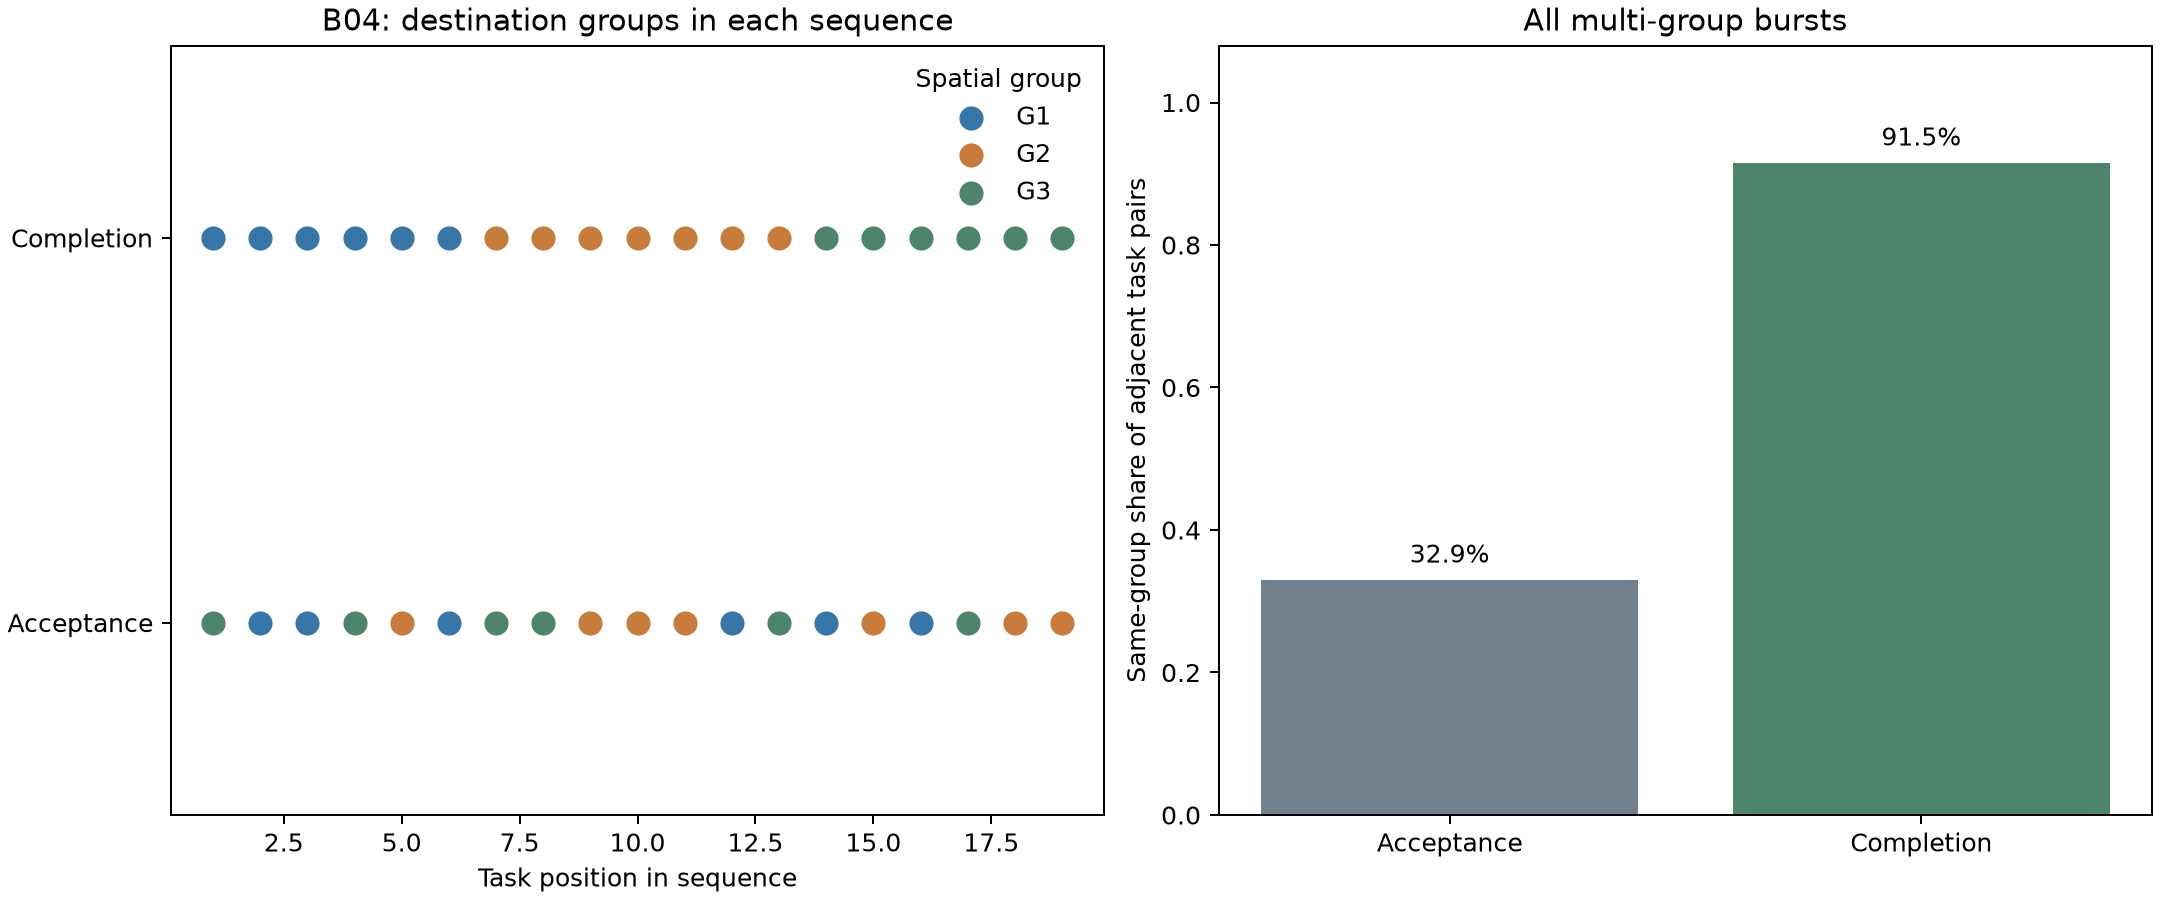

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def analyze(df, index):
    import matplotlib.dates as mdates

    d = df.copy()
    d["accept_time"] = pd.to_datetime(d.accept_time)
    b = d.groupby("acceptance_burst_id").agg(
        tasks=("delivery_task_id", "size"),
        groups=("spatial_group", "nunique"),
        start=("accept_time", "min"),
        end=("accept_time", "max"),
    )
    b["size"] = np.where(b.tasks <= 4, "small", "large")
    within = (
        d.sort_values("accept_time")
        .groupby("acceptance_burst_id")
        .accept_time.diff()
        .dt.total_seconds()
        .dropna()
        / 60
    )
    between = (b.start - b.end.shift()).dt.total_seconds().dropna() / 60
    rates = []
    for column in ["acceptance_order_in_burst", "completion_order_in_burst"]:
        pairs = []
        for _, q in d.groupby("acceptance_burst_id"):
            if q.spatial_group.nunique() > 1:
                values = q.sort_values(column).spatial_group.to_numpy()
                pairs.extend(values[1:] == values[:-1])
        rates.append(float(np.mean(pairs)))
    split = b.groupby("size")["groups"].apply(lambda v: float((v > 1).mean()))
    if index == 0:
        evidence = dict(
            acceptance_bursts=len(b),
            accepted_tasks=len(d),
            maximum_within_burst_gap_min=round(float(within.max()), 2),
            minimum_between_burst_gap_min=round(float(between.min()), 2),
        )
        fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), constrained_layout=True)
        axes[0].scatter(
            d.accept_time, np.zeros(len(d)), marker="|", s=200, color="#c77c3d"
        )
        for name, row in b.iterrows():
            axes[0].text(
                row.start + (row.end - row.start) / 2,
                0.12,
                f"{name}\n{row.tasks} tasks",
                ha="center",
                fontsize=9,
            )
        axes[0].set(
            yticks=[],
            ylim=(-0.15, 0.35),
            title=f"{len(d)} acceptances in {len(b)} distinct bursts",
        )
        axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        axes[1].hist(
            [within, between],
            bins=np.linspace(0, max(between) + 5, 30),
            label=["Within burst", "Between bursts"],
        )
        axes[1].set(xlabel="Acceptance gap (minutes)", ylabel="Number of gaps")
        axes[1].legend(frameon=False)
    elif index == 1:
        evidence = dict(
            same_group_adjacency_in_acceptance_sequence=round(rates[0], 3),
            same_group_adjacency_in_completion_sequence=round(rates[1], 3),
        )
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
        q = d[d.acceptance_burst_id == "B04"]
        palette = dict(
            zip(sorted(q.spatial_group.unique()), ["#3976a8", "#c77c3d", "#4f846c"])
        )
        for y, column in enumerate(
            ["acceptance_order_in_burst", "completion_order_in_burst"]
        ):
            for group, rows in q.groupby("spatial_group"):
                axes[0].scatter(
                    rows[column],
                    np.full(len(rows), y),
                    color=palette[group],
                    s=75,
                    label=group.split("_")[-1] if y == 0 else None,
                )
        axes[0].set(
            yticks=[0, 1],
            yticklabels=["Acceptance", "Completion"],
            ylim=(-0.5, 1.5),
            xlabel="Task position in sequence",
            title="B04: destination groups in each sequence",
        )
        axes[0].legend(title="Spatial group", frameon=False)
        axes[1].bar(["Acceptance", "Completion"], rates, color=["#71808d", "#4f846c"])
        for i, rate in enumerate(rates):
            axes[1].text(i, rate + 0.025, f"{rate:.1%}", ha="center")
        axes[1].set(
            ylim=(0, 1.08),
            ylabel="Same-group share of adjacent task pairs",
            title="All multi-group bursts",
        )
    else:
        evidence = dict(
            small_burst_split_rate=round(split["small"], 3),
            large_burst_split_rate=round(split["large"], 3),
        )
        fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
        for name, row in b.iterrows():
            ax.scatter(
                row.tasks,
                row["groups"],
                s=90,
                color="#3976a8" if row["size"] == "small" else "#c77c3d",
            )
            ax.annotate(
                name,
                (row.tasks, row["groups"]),
                xytext=(5, 7),
                textcoords="offset points",
            )
        ax.set(
            xlabel="Tasks accepted in burst (small: ≤4)",
            ylabel="Distinct destination groups",
            yticks=[1, 2, 3],
            ylim=(0.7, 3.4),
            title="Burst size and spatial splitting",
        )
    print(evidence)
    return evidence


evidence = analyze(df, 1)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/within_burst_spatial_sequence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "within_burst_acceptance_and_completion_sequence",
  "insight_type": "factor_relationship",
  "insight": "Within the same acceptance burst, tasks with nearby destinations tend to be completed consecutively even when they were accepted in a different order.",
  "insight_value": {
    "same_group_adjacency_in_acceptance_sequence": 0.329,
    "same_group_adjacency_in_completion_sequence": 0.915
  },
  "plot": {
    "plot_type": "group_sequence_and_adjacency_rates",
    "title": "Spatial Completion Sequence Within Bursts",
    "file": "visualizations/within_burst_spatial_sequence.png",
    "description": "B04 destination-group sequences and same-group adjacency rates across all multi-group bursts."
  },
  "question": "Within a burst, does completion order follow acceptance order or destination proximity?",
  "actionable_insight": "Compare spatial-group adjacency in the acceptance and completion sequences for every multi-group burst.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef analyze(df, index):\n    import matplotlib.dates as mdates\n    d = df.copy()\n    d['accept_time'] = pd.to_datetime(d.accept_time)\n    b = d.groupby('acceptance_burst_id').agg(\n        tasks=('delivery_task_id', 'size'), groups=('spatial_group', 'nunique'),\n        start=('accept_time', 'min'), end=('accept_time', 'max'))\n    b['size'] = np.where(b.tasks <= 4, 'small', 'large')\n    within = d.sort_values('accept_time').groupby('acceptance_burst_id').accept_time.diff().dt.total_seconds().dropna()/60\n    between = (b.start-b.end.shift()).dt.total_seconds().dropna()/60\n    rates = []\n    for column in ['acceptance_order_in_burst', 'completion_order_in_burst']:\n        pairs = []\n        for _, q in d.groupby('acceptance_burst_id'):\n            if q.spatial_group.nunique() > 1:\n                values = q.sort_values(column).spatial_group.to_numpy()\n                pairs.extend(values[1:] == values[:-1])\n        rates.append(float(np.mean(pairs)))\n    split = b.groupby('size')['groups'].apply(lambda v: float((v > 1).mean()))\n    if index == 0:\n        evidence = dict(acceptance_bursts=len(b), accepted_tasks=len(d),\n            maximum_within_burst_gap_min=round(float(within.max()), 2),\n            minimum_between_burst_gap_min=round(float(between.min()), 2))\n        fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), constrained_layout=True)\n        axes[0].scatter(d.accept_time, np.zeros(len(d)), marker='|', s=200, color='#c77c3d')\n        for name, row in b.iterrows():\n            axes[0].text(row.start+(row.end-row.start)/2, .12, f'{name}\\n{row.tasks} tasks', ha='center', fontsize=9)\n        axes[0].set(yticks=[], ylim=(-.15, .35), title=f'{len(d)} acceptances in {len(b)} distinct bursts')\n        axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))\n        axes[1].hist([within, between], bins=np.linspace(0, max(between)+5, 30), label=['Within burst', 'Between bursts'])\n        axes[1].set(xlabel='Acceptance gap (minutes)', ylabel='Number of gaps')\n        axes[1].legend(frameon=False)\n    elif index == 1:\n        evidence = dict(same_group_adjacency_in_acceptance_sequence=round(rates[0], 3),\n            same_group_adjacency_in_completion_sequence=round(rates[1], 3))\n        fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)\n        q = d[d.acceptance_burst_id == 'B04']\n        palette = dict(zip(sorted(q.spatial_group.unique()), ['#3976a8', '#c77c3d', '#4f846c']))\n        for y, column in enumerate(['acceptance_order_in_burst', 'completion_order_in_burst']):\n            for group, rows in q.groupby('spatial_group'):\n                axes[0].scatter(rows[column], np.full(len(rows), y), color=palette[group], s=75,\n                    label=group.split('_')[-1] if y == 0 else None)\n        axes[0].set(yticks=[0, 1], yticklabels=['Acceptance', 'Completion'], ylim=(-.5, 1.5),\n            xlabel='Task position in sequence', title='B04: destination groups in each sequence')\n        axes[0].legend(title='Spatial group', frameon=False)\n        axes[1].bar(['Acceptance', 'Completion'], rates, color=['#71808d', '#4f846c'])\n        for i, rate in enumerate(rates): axes[1].text(i, rate+.025, f'{rate:.1%}', ha='center')\n        axes[1].set(ylim=(0, 1.08), ylabel='Same-group share of adjacent task pairs', title='All multi-group bursts')\n    else:\n        evidence = dict(small_burst_split_rate=round(split['small'], 3), large_burst_split_rate=round(split['large'], 3))\n        fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)\n        for name, row in b.iterrows():\n            ax.scatter(row.tasks, row['groups'], s=90, color='#3976a8' if row['size']=='small' else '#c77c3d')\n            ax.annotate(name, (row.tasks, row['groups']), xytext=(5, 7), textcoords='offset points')\n        ax.set(xlabel='Tasks accepted in burst (small: ≤4)', ylabel='Distinct destination groups',\n            yticks=[1, 2, 3], ylim=(.7, 3.4), title='Burst size and spatial splitting')\n    print(evidence)\n    return evidence\n\nevidence = analyze(df, 1)\nplt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "completion_time",
    "delivery_position",
    "task_id"
  ]
}

### **Question 3**: Are larger acceptance bursts divided among more destination areas than small bursts?

#### Analysis action

Count distinct spatial groups per burst and compare split rates between small and large bursts.

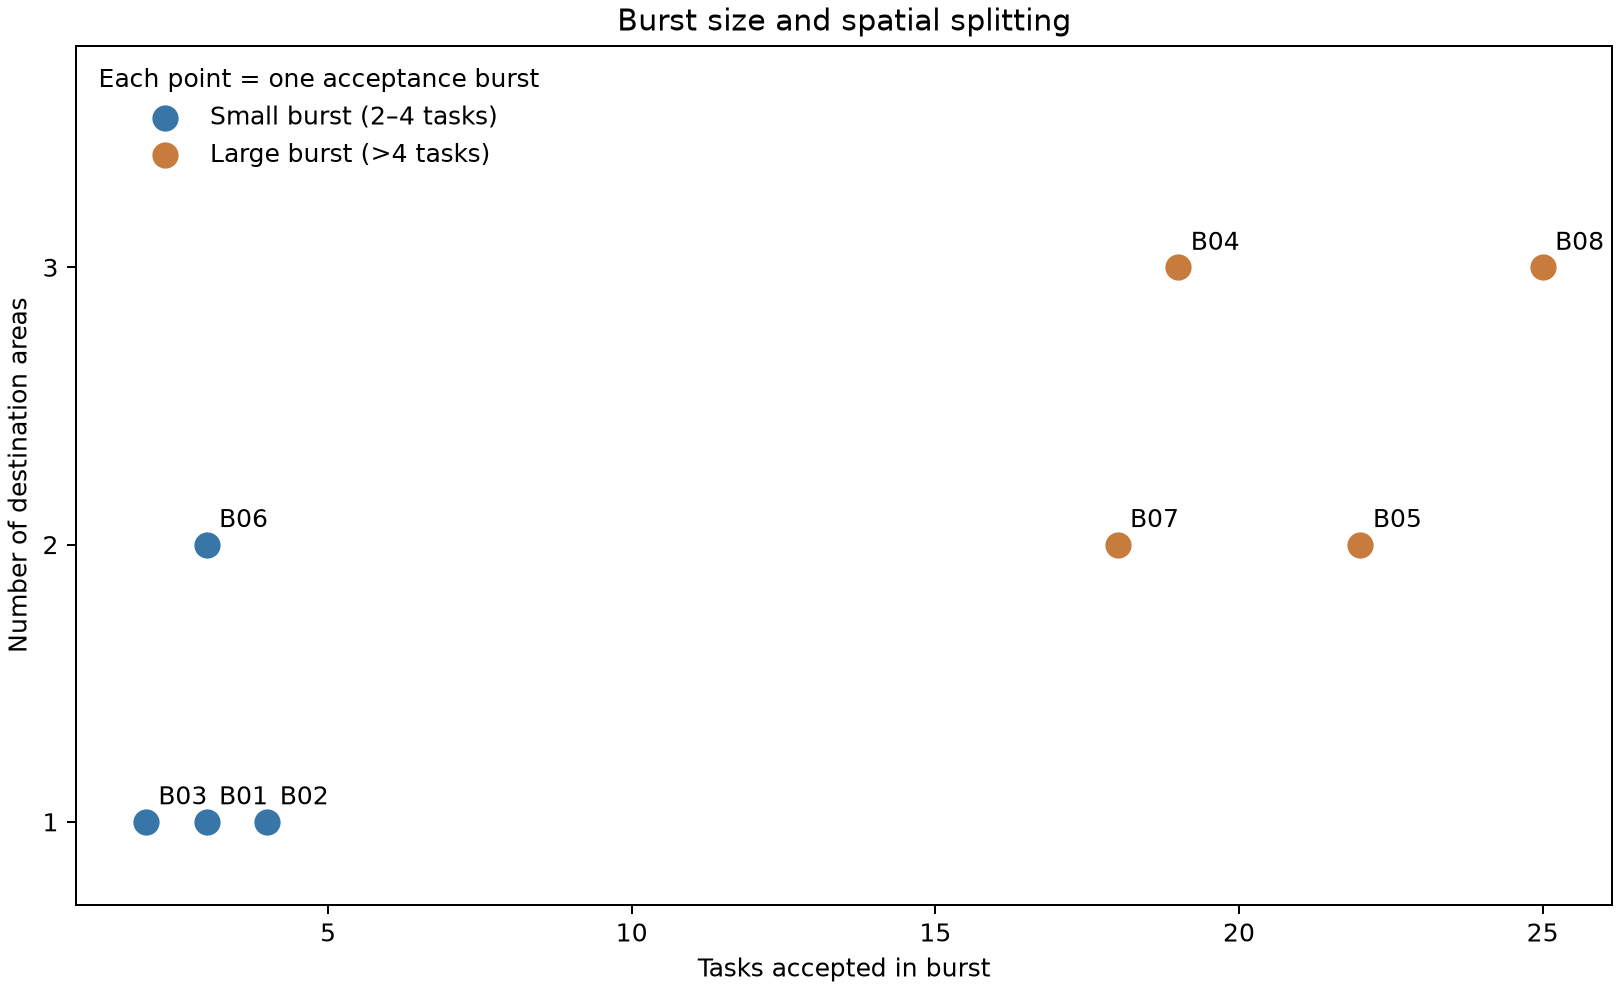

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def analyze(df, index):
    import matplotlib.dates as mdates

    d = df.copy()
    d["accept_time"] = pd.to_datetime(d.accept_time)
    b = d.groupby("acceptance_burst_id").agg(
        tasks=("delivery_task_id", "size"),
        groups=("spatial_group", "nunique"),
        start=("accept_time", "min"),
        end=("accept_time", "max"),
    )
    b["size"] = np.where(b.tasks <= 4, "small", "large")
    within = (
        d.sort_values("accept_time")
        .groupby("acceptance_burst_id")
        .accept_time.diff()
        .dt.total_seconds()
        .dropna()
        / 60
    )
    between = (b.start - b.end.shift()).dt.total_seconds().dropna() / 60
    rates = []
    for column in ["acceptance_order_in_burst", "completion_order_in_burst"]:
        pairs = []
        for _, q in d.groupby("acceptance_burst_id"):
            if q.spatial_group.nunique() > 1:
                values = q.sort_values(column).spatial_group.to_numpy()
                pairs.extend(values[1:] == values[:-1])
        rates.append(float(np.mean(pairs)))
    split = b.groupby("size")["groups"].apply(lambda v: float((v > 1).mean()))
    if index == 0:
        evidence = dict(
            acceptance_bursts=len(b),
            accepted_tasks=len(d),
            maximum_within_burst_gap_min=round(float(within.max()), 2),
            minimum_between_burst_gap_min=round(float(between.min()), 2),
        )
        fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), constrained_layout=True)
        axes[0].scatter(
            d.accept_time, np.zeros(len(d)), marker="|", s=200, color="#c77c3d"
        )
        for name, row in b.iterrows():
            axes[0].text(
                row.start + (row.end - row.start) / 2,
                0.12,
                f"{name}\n{row.tasks} tasks",
                ha="center",
                fontsize=9,
            )
        axes[0].set(
            yticks=[],
            ylim=(-0.15, 0.35),
            title=f"{len(d)} acceptances in {len(b)} distinct bursts",
        )
        axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        axes[1].hist(
            [within, between],
            bins=np.linspace(0, max(between) + 5, 30),
            label=["Within burst", "Between bursts"],
        )
        axes[1].set(xlabel="Acceptance gap (minutes)", ylabel="Number of gaps")
        axes[1].legend(frameon=False)
    elif index == 1:
        evidence = dict(
            same_group_adjacency_in_acceptance_sequence=round(rates[0], 3),
            same_group_adjacency_in_completion_sequence=round(rates[1], 3),
        )
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
        q = d[d.acceptance_burst_id == "B04"]
        palette = dict(
            zip(sorted(q.spatial_group.unique()), ["#3976a8", "#c77c3d", "#4f846c"])
        )
        for y, column in enumerate(
            ["acceptance_order_in_burst", "completion_order_in_burst"]
        ):
            for group, rows in q.groupby("spatial_group"):
                axes[0].scatter(
                    rows[column],
                    np.full(len(rows), y),
                    color=palette[group],
                    s=75,
                    label=group.split("_")[-1] if y == 0 else None,
                )
        axes[0].set(
            yticks=[0, 1],
            yticklabels=["Acceptance", "Completion"],
            ylim=(-0.5, 1.5),
            xlabel="Task position in sequence",
            title="B04: destination groups in each sequence",
        )
        axes[0].legend(title="Spatial group", frameon=False)
        axes[1].bar(["Acceptance", "Completion"], rates, color=["#71808d", "#4f846c"])
        for i, rate in enumerate(rates):
            axes[1].text(i, rate + 0.025, f"{rate:.1%}", ha="center")
        axes[1].set(
            ylim=(0, 1.08),
            ylabel="Same-group share of adjacent task pairs",
            title="All multi-group bursts",
        )
    else:
        evidence = dict(
            small_burst_split_rate=round(split["small"], 3),
            large_burst_split_rate=round(split["large"], 3),
        )
        fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
        for size, color, label in [
            ("small", "#3976a8", "Small burst (2–4 tasks)"),
            ("large", "#c77c3d", "Large burst (>4 tasks)"),
        ]:
            subset = b[b["size"] == size]
            ax.scatter(subset.tasks, subset["groups"], s=90, color=color, label=label)
        for name, row in b.iterrows():
            ax.annotate(
                name,
                (row.tasks, row["groups"]),
                xytext=(5, 7),
                textcoords="offset points",
            )
        ax.set(
            xlabel="Tasks accepted in burst",
            ylabel="Number of destination areas",
            yticks=[1, 2, 3],
            ylim=(0.7, 3.8),
            title="Burst size and spatial splitting",
        )
        ax.legend(
            title="Each point = one acceptance burst", loc="upper left", frameon=False
        )
    print(evidence)
    return evidence


evidence = analyze(df, 2)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/burst_size_spatial_groups.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "burst_size_and_destination_group_count",
  "insight_type": "group_comparison",
  "insight": "Larger acceptance bursts are more often split into several spatial groups, whereas small bursts are usually completed within one local area.",
  "insight_value": {
    "small_burst_split_rate": 0.25,
    "large_burst_split_rate": 1.0
  },
  "plot": {
    "plot_type": "burst_level_scatter",
    "title": "Burst Size and Spatial Splitting",
    "file": "visualizations/burst_size_spatial_groups.png",
    "description": "Each acceptance burst is plotted by task count and distinct destination-group count."
  },
  "question": "Are larger acceptance bursts divided among more destination areas than small bursts?",
  "actionable_insight": "Count distinct spatial groups per burst and compare split rates between small and large bursts.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef analyze(df, index):\n    import matplotlib.dates as mdates\n    d = df.copy()\n    d['accept_time'] = pd.to_datetime(d.accept_time)\n    b = d.groupby('acceptance_burst_id').agg(\n        tasks=('delivery_task_id', 'size'), groups=('spatial_group', 'nunique'),\n        start=('accept_time', 'min'), end=('accept_time', 'max'))\n    b['size'] = np.where(b.tasks <= 4, 'small', 'large')\n    within = d.sort_values('accept_time').groupby('acceptance_burst_id').accept_time.diff().dt.total_seconds().dropna()/60\n    between = (b.start-b.end.shift()).dt.total_seconds().dropna()/60\n    rates = []\n    for column in ['acceptance_order_in_burst', 'completion_order_in_burst']:\n        pairs = []\n        for _, q in d.groupby('acceptance_burst_id'):\n            if q.spatial_group.nunique() > 1:\n                values = q.sort_values(column).spatial_group.to_numpy()\n                pairs.extend(values[1:] == values[:-1])\n        rates.append(float(np.mean(pairs)))\n    split = b.groupby('size')['groups'].apply(lambda v: float((v > 1).mean()))\n    if index == 0:\n        evidence = dict(acceptance_bursts=len(b), accepted_tasks=len(d),\n            maximum_within_burst_gap_min=round(float(within.max()), 2),\n            minimum_between_burst_gap_min=round(float(between.min()), 2))\n        fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), constrained_layout=True)\n        axes[0].scatter(d.accept_time, np.zeros(len(d)), marker='|', s=200, color='#c77c3d')\n        for name, row in b.iterrows():\n            axes[0].text(row.start+(row.end-row.start)/2, .12, f'{name}\\n{row.tasks} tasks', ha='center', fontsize=9)\n        axes[0].set(yticks=[], ylim=(-.15, .35), title=f'{len(d)} acceptances in {len(b)} distinct bursts')\n        axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))\n        axes[1].hist([within, between], bins=np.linspace(0, max(between)+5, 30), label=['Within burst', 'Between bursts'])\n        axes[1].set(xlabel='Acceptance gap (minutes)', ylabel='Number of gaps')\n        axes[1].legend(frameon=False)\n    elif index == 1:\n        evidence = dict(same_group_adjacency_in_acceptance_sequence=round(rates[0], 3),\n            same_group_adjacency_in_completion_sequence=round(rates[1], 3))\n        fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)\n        q = d[d.acceptance_burst_id == 'B04']\n        palette = dict(zip(sorted(q.spatial_group.unique()), ['#3976a8', '#c77c3d', '#4f846c']))\n        for y, column in enumerate(['acceptance_order_in_burst', 'completion_order_in_burst']):\n            for group, rows in q.groupby('spatial_group'):\n                axes[0].scatter(rows[column], np.full(len(rows), y), color=palette[group], s=75,\n                    label=group.split('_')[-1] if y == 0 else None)\n        axes[0].set(yticks=[0, 1], yticklabels=['Acceptance', 'Completion'], ylim=(-.5, 1.5),\n            xlabel='Task position in sequence', title='B04: destination groups in each sequence')\n        axes[0].legend(title='Spatial group', frameon=False)\n        axes[1].bar(['Acceptance', 'Completion'], rates, color=['#71808d', '#4f846c'])\n        for i, rate in enumerate(rates): axes[1].text(i, rate+.025, f'{rate:.1%}', ha='center')\n        axes[1].set(ylim=(0, 1.08), ylabel='Same-group share of adjacent task pairs', title='All multi-group bursts')\n    else:\n        evidence = dict(small_burst_split_rate=round(split['small'], 3), large_burst_split_rate=round(split['large'], 3))\n        fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)\n        for size, color, label in [('small', '#3976a8', 'Small burst (2–4 tasks)'),\n                                   ('large', '#c77c3d', 'Large burst (>4 tasks)')]:\n            subset = b[b['size'] == size]\n            ax.scatter(subset.tasks, subset['groups'], s=90, color=color, label=label)\n        for name, row in b.iterrows():\n            ax.annotate(name, (row.tasks, row['groups']), xytext=(5, 7), textcoords='offset points')\n        ax.set(xlabel='Tasks accepted in burst', ylabel='Number of destination areas',\n            yticks=[1, 2, 3], ylim=(.7, 3.8), title='Burst size and spatial splitting')\n        ax.legend(title='Each point = one acceptance burst', loc='upper left', frameon=False)\n    print(evidence)\n    return evidence\n\nevidence = analyze(df, 2)\nplt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "delivery_position",
    "task_id"
  ]
}

### Summary of Findings (Flag 15)

Accepted tasks arrive in compact bursts separated by much longer gaps. The courier reorganizes interleaved acceptance order into locally consecutive destination groups, and large bursts are much more often divided across several local areas than small bursts.